In [1]:
!pip install rioxarray --quiet

In [2]:
import os
import glob
import datetime
import xarray as xr
import rioxarray as rio
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

### **Step 2 - Create a .zip file/Upload an existing .zip files**
We will now upload a .zip file containing a series of .tif files to our session: data.zip.
   
Execute the command below and navigate to where you have saved the .zip file from Topic3_N01 in your local drive.

(If you are uploading your own .tif files, you can first create a .zip archive from these files, you may need to install compression software such as 7zip (https://www.7-zip.org/) or WinRAR (https://www.win-rar.com/) to perform this operation.)

In [3]:
#To upload file.
uploaded = files.upload()

Saving data (2).zip to data (2).zip


### **Step 3 - Unzip files**
Unzip the file you have uploaded.
The command is:
 !unzip 'file_path.zip' -d 'folder_to_unzip_path'
Replace the file name in the cell below with the name of your own file. You can find the path to your file by clicking on the 3 dots next to the file name in your file explorer to the left and selecting *Copy path*. (If you do not see your files to the left, click on the folder icon to expand the Files panel).


In [4]:
# unzip the uploaded zipfile
!unzip '/content/data (2).zip'

Archive:  /content/data (2).zip
   creating: content/output/
   creating: content/output/L3-AETI-D/
   creating: content/output/L1-AETI-D/
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-06-01.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-02-21.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-10-01.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-11-11.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-07-01.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-03-01.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-05-11.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-04-01.tif  
  inflating: content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-

### **Step 4 - Opening and inspecting one .tif file**
Before performing any operations let us open one of our TIFF files using the rioxarray package.

**NOTE**: all paths used in the following script are based on where the files are located when following all steps, if your data is stored elsewhere you have to update the relative path

In [5]:
# Open first raster from your unzipped files and mask out nan values
ds = rio.open_rasterio('/content/content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-01-01.tif')
ds = ds.where(ds!=ds.attrs['_FillValue'])

In [6]:
# Inspect the contents - How many pixels does the raster contain?
ds

<xarray.DataArray (band: 1, y: 382, x: 344)> Size: 1MB
array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(1, 382, 344))
Coordinates:
  * band         (band) int64 8B 1
  * y            (y) float64 3kB 8.096 8.093 8.09 8.087 ... 6.986 6.983 6.98
  * x            (x) float64 3kB 4.053 4.056 4.059 4.062 ... 5.052 5.055 5.058
    spatial_ref  int64 8B 0
Attributes: (12/13)
    AREA_OR_POINT:            Area
    end_date:                 2025-01-10
    long_name:                2025-01-01
    number_of_days:           10
    original_units:           mm/day
    overview:                 NONE
    ...                       ...
    temporal_resolution:      Dekad
    units:                    mm/dekad
    units_conversion_factor:  10
    _FillValue:               -9999.0
    scale_factor:             1.0
    add_offset:               0.0

In [7]:
#The values contained are stored as an array with each value representing one pixel.
ds.values

array([[[nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        ...,
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan],
        [nan, nan, nan, ..., nan, nan, nan]]], shape=(1, 382, 344))

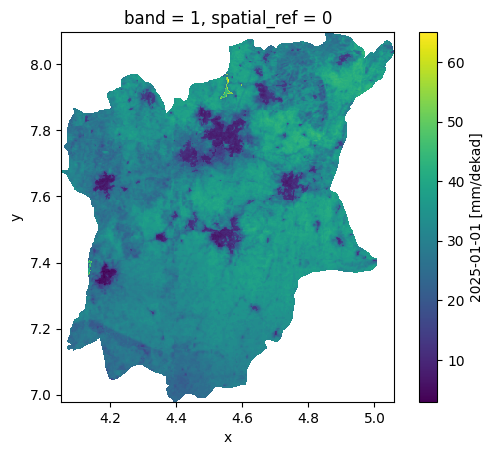

In [8]:
# We can produce a quick map of our data using the plot function
ds[0].plot()
ax = plt.gca()
ax.set_aspect('equal', adjustable='box') #this command will equally space the x and y units

In [9]:
#check the min, max and mean values
print(np.nanmin(ds.values), np.nanmax(ds.values), np.nanmean(ds.values))

3.0 65.0 30.614820196149655


### **Step 5 - Seasonal AETI from dekadal AETI**
We will now create one raster file which contains the seasonal AETI value for our area. For this we simply need to loop through the AETI files, and add up the values.   
The glob function allows us to list files in a folder matching a specific pattern.
For example:  
`glob.glob('/content/content/output/L3-AETI-D/*.tif')  `  

will produce a list of all files with the .tif extension contained in the *L3-AETI-D* folder,
while:   
`glob.glob('/content/content/output/L3-AETI-D/*2022-10*.tif')`

will produce a list of all files with the .tif extension which also have the string *202210* in the filename - these will be all of the files from October 2022.


In [19]:
# Example to get files from January 2025
glob.glob('/content/content/output/L1-AETI-D/*2025-01*.tif')

['/content/content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-01-21.tif',
 '/content/content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-01-11.tif',
 '/content/content/output/L1-AETI-D/osun_state_L1-AETI-D_NONE_dekad_converted_2025-01-01.tif']

Let's produce a seasonal file for our whole time period (this will add up all the files in the folder):

In [14]:
for i, fp in enumerate(glob.glob('/content/content/output/L1-AETI-D/*.tif')):
  fn = os.path.basename(fp)
  # OPEN DATA
  ds = rio.open_rasterio(fp)
  ds = ds.where(ds!=ds.attrs['_FillValue'])
  if i == 0:
    ds_sum = ds #Initialize sum if we are looking at the first raster
  else:
    ds_sum += ds #This is the python way of writing ds_sum = ds_sum + ds

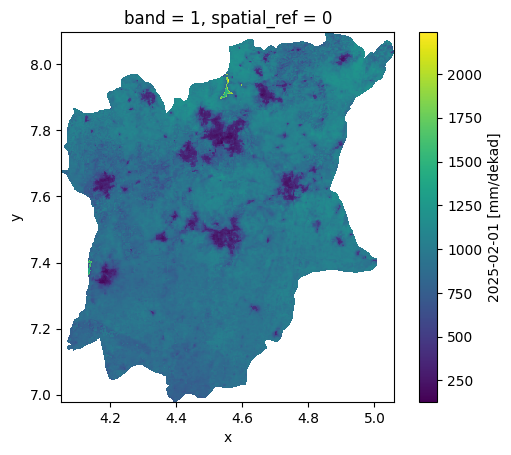

In [15]:
ds_sum.plot()
ax = plt.gca()
ax.set_aspect('equal', adjustable='box') #this command will equally space the x and y units

In [ ]:
# Save the seasonal sum to a TIFF file and download to your local drive
ds_sum.rio.to_raster("Wad_Helal_seasonal_AETI.tif")
files.download(r'/content/Wad_Helal_seasonal_AETI.tif')